In [1]:
import awkward as ak
import uproot
from coffea.nanoevents import NanoEventsFactory, NanoAODSchema
from coffea.nanoevents.methods import vector
import numpy as np

In [2]:
import coffea
coffea.__version__

'0.7.12'

In [3]:
fileset = {
    "WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____4_": 
    [
            "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-100To250_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/100000/8A16FAF9-40C4-9042-A888-CC6FF79132BD.root"
        #             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/130000/7FFCDC32-7714-6E4F-B67D-D5249140BD2F.root",
#             "root://cmsxrootd.fnal.gov//store/mc/RunIISummer20UL18NanoAODv9/WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8/NANOAODSIM/106X_upgrade2018_realistic_v16_L1v1-v1/130000/D62C3915-5A89-0245-B798-CA424003CE1E.root"
        ],
}
fname = fileset["WJetsToLNu_Pt-250To400_MatchEWPDG20_TuneCP5_13TeV-amcatnloFXFX-pythia8____4_"][0]
events = NanoEventsFactory.from_root(fname, schemaclass=NanoAODSchema).events()

In [5]:
from coffea import util
corrections = util.load("../../data/corrections.coffea")
get_ele_trig_weight = corrections['get_ele_trig_weight']['2018']

In [6]:
corrections = util.load("../../data/corrections.coffea")
get_deepflav_weight = corrections['get_btag_weight_postVFP']['deepflav']['2018']

common = util.load('../../data/common.coffea')
deepflavWPs = common['btagWPs']['deepflav']['2018']

_ids = util.load("../../data/ids.coffea")
isLooseElectron = _ids['isLooseElectron']
isTightElectron = _ids['isTightElectron']
isLooseMuon = _ids['isLooseMuon']
isTightMuon = _ids['isTightMuon']
isLooseTau = _ids['isLooseTau']
isLoosePhoton = _ids['isLoosePhoton']
isTightPhoton = _ids['isTightPhoton']
isGoodJet = _ids['isGoodJet']
isHEMJet = _ids['isHEMJet']
get_deepflav_weight = corrections['get_btag_weight_postVFP']['deepflav']['2018']

In [7]:
year = '2018'
met = events.MET
met["T"] = ak.zip({"pt": met.pt, "phi": met.phi}, 
                  with_name="PolarTwoVector", 
                  behavior=vector.behavior)

calomet = events.CaloMET
puppimet = events.PuppiMET
puppimet["T"] = ak.zip({"pt": puppimet.pt, "phi": puppimet.phi}, 
                  with_name="PolarTwoVector", 
                  behavior=vector.behavior)

###
# Initialize physics objects
###


mu = events.Muon
mu['isloose'] = isLooseMuon(mu.pt, mu.eta, mu.pfRelIso04_all, mu.looseId, year, events.Muon.isPFcand,
                           events.Muon.isGlobal,
                           events.Muon.isTracker)
mu['istight'] = isTightMuon(mu.pt, mu.eta, mu.pfRelIso04_all,  mu.looseId, year, events.Muon.isPFcand,
                                   events.Muon.isGlobal,
                                   events.Muon.isTracker)
mu["T"] = ak.zip({"pt": mu.pt, "phi": mu.phi}, 
          with_name="PolarTwoVector", 
          behavior=vector.behavior)
mu['p4'] = ak.zip({
                    "pt": mu.pt,
                    "eta": mu.eta,
                    "phi": mu.phi,
                    "mass": mu.mass},
                    with_name="PtEtaPhiMLorentzVector",
)


mu_loose = mu[ak.values_astype(mu.isloose, np.bool)]
mu_tight = mu[ak.values_astype(mu.istight, np.bool)]
ak.num(mu, axis=1)
mu_ntot = ak.num(mu, axis=1)
mu_nloose = ak.num(mu_loose, axis=1)
mu_ntight = ak.num(mu_tight, axis=1)
leading_mu = mu_tight[:,:1]


e = events.Electron
event_size = len(e)


e['isclean'] = ak.all(e.metric_table(mu_loose) > 0.3, axis=-1)
e['isloose'] = isLooseElectron(e.pt, e.eta+e.deltaEtaSC, e.dxy, e.dz, e.cutBased, year)
e['istight'] = isTightElectron(e.pt, e.eta+e.deltaEtaSC, e.dxy, e.dz, e.cutBased, year)
#         e['T'] = TVector2Array.from_polar(e.pt, e.phi)
e["T"] = ak.zip({"pt": e.pt, "phi": e.phi}, 
          with_name="PolarTwoVector", 
          behavior=vector.behavior)
e['p4'] = ak.zip({
                    "pt": e.pt,
                    "eta": e.eta,
                    "phi": e.phi,
                    "mass": e.mass},
                    with_name="PtEtaPhiMLorentzVector",
)
e_clean = e[ak.values_astype(e.isclean, np.bool)]
e_loose = e_clean[ak.values_astype(e_clean.isloose, np.bool)]
e_tight = e_clean[ak.values_astype(e_clean.istight, np.bool)]
e_ntot = ak.num(e, axis=1)
e_nloose = ak.num(e_loose, axis=1)

#         e_nloose = e_loose.counts
e_ntight = ak.num(e_tight, axis=1)
leading_e = e_tight[:,:1]


tau = events.Tau
tau['isclean'] = ak.all(tau.metric_table(mu_loose) > 0.4, axis=-1) & ak.all(tau.metric_table(e_loose) > 0.4, axis=-1)
#         ak.all(tau.metric_table(mu_loose) > 0.4, axis=-1)
try:
    tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayMode,tau.idDeepTau2017v2p1VSjet,year)
except:
    tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayModeOldDMs,tau.idDeepTau2017v2p1VSjet,year)
else: 
    tau['isloose']=isLooseTau(tau.pt,tau.eta,tau.idDecayModeNewDMs,tau.idDeepTau2017v2p1VSjet,year)

tau_clean = tau[ak.values_astype(tau.isclean, np.bool)]

tau_loose = tau_clean[ak.values_astype(tau_clean.isloose, np.bool)]
tau_ntot = ak.num(tau, axis=1)
tau_nloose = ak.num(tau_loose, axis=1)

pho = events.Photon
pho['isclean'] = ak.all(pho.metric_table(mu_loose) > 0.4, axis=-1) & ak.all(pho.metric_table(e_loose) > 0.4, axis=-1)
_id = 'cutBased'
if year == '2016':
    _id = 'cutBased'
pho['isloose'] = isLoosePhoton(pho.pt, pho.eta, pho[_id], year) & (pho.electronVeto)  # added electron veto flag
pho['istight'] = isTightPhoton(pho.pt, pho[_id], year) & (pho.isScEtaEB) & (pho.electronVeto)  # tight photons are barrel only

pho["T"] = ak.zip({"pt": pho.pt, "phi": pho.phi}, 
          with_name="PolarTwoVector", 
          behavior=vector.behavior)

pho_clean = pho[ak.values_astype(pho.isclean, np.bool)]
pho_loose = pho_clean[ak.values_astype(pho_clean.isloose, np.bool)]
pho_tight = pho_clean[ak.values_astype(pho_clean.istight, np.bool)]
pho_ntot = ak.num(pho,axis=1)
pho_nloose = ak.num(pho_loose, axis=1)
pho_ntight = ak.num(pho_tight, axis=1)
leading_pho = pho[:,:1] #new way to define leading photon
leading_pho = leading_pho[ak.values_astype(leading_pho.isclean, np.bool)]

leading_pho = leading_pho[ak.values_astype(leading_pho.istight, np.bool)]
leading_pho = leading_pho[ak.values_astype(leading_pho.istight, np.bool)]

j = events.Jet
def jetcleaning(j, mu_loose, e_loose, pho_loose, r):
    NumNeutralParticles = (j.nConstituents-j.nElectrons-j.nMuons)
    NumConst = j.nConstituents
    NHF = j.neHEF
    NEMF = j.neEmEF
    CHF = j.chHEF
    MUF = j.muEF
    CEMF = j.chEmEF
    CHM = j.nElectrons+j.nMuons
    #First we find all the good jets
    j_isgood_mask = isGoodJet(j.pt, j.eta, j.jetId, j.puId,NHF, NEMF, NumConst, MUF, CHF, CHM, CEMF, year=year)
#             j_good = j[j_isgood_mask] # [ [True, False, False], [True],...[False, True] ]

    #then for all the good jets we select isolated jets with muons and electron and photons
    jetMuMask = ak.any((j.metric_table(mu_loose)<0.4), axis=2)
    jetEleMask = ak.any((j.metric_table(e_loose)<0.4), axis=2)
    jetPhoMask = ak.any((j.metric_table(pho_loose)<0.4), axis=2)
            
    j_isclean_mask = (~jetMuMask & ~jetEleMask & ~jetPhoMask) # this is event based [True, False,..False]
    return(j_isgood_mask, j_isclean_mask)

#         j['isgood'] = isGoodJet(j.pt, j.eta, j.jetId, j.puId,NHF, NEMF, NumConst, MUF, CHF, CHM, CEMF, year=year)
j['isHEM'] = isHEMJet(j.pt, j.eta, j.phi)
# j['isdcsvL'] = (j.btagDeepB>deepcsvWPs['loose'])
# j['isdflvL'] = (j.btagDeepFlavB>deepflavWPs['loose'])
j['isdflvM'] = (j.btagDeepFlavB > deepflavWPs['medium']) ## from Rishab
# j['isdcsvM'] = (j.btagDeepB > deepcsvWPs['medium']) ## from Rishabh

j["T"] = ak.zip({"pt": j.pt, "phi": j.phi}, 
          with_name="PolarTwoVector", 
          behavior=vector.behavior)
j['p4'] = ak.zip({
"pt": j.pt,
"eta": j.eta,
"phi": j.phi,
"mass": j.mass},
with_name="PtEtaPhiMLorentzVector",
)


j_good_mask, j_clean_mask = jetcleaning(j, mu_loose, e_loose, pho_loose, 0.4)

j['isgood'] = j_good_mask
j['isclean'] = j_clean_mask
j_good = j[j.isgood]       
j_clean = j[j_clean_mask]

j_good_clean = j[j_good_mask & j_clean_mask]
j_ngood_clean = ak.num(j_good_clean, axis=1)
j_ngood = ak.num(j_good, axis=1)
j_nclean = ak.num(j_clean, axis=1)

j_HEM = j[ak.values_astype(j.isHEM, np.bool)] 
j_nHEM = ak.num(j_HEM, axis=1)

j_dflvM = j_good_clean[ak.values_astype(j_good_clean.isdflvM, np.bool)]
j_ndflvM = ak.num(j_dflvM, axis=1)
leading_j = j_good_clean[:,:1]
atleast_one_jet_with_pt_grt_50 = (j_nclean>0)&(ak.any(leading_j.pt>70, axis=1))


In [8]:
from coffea.util import load, save
from coffea import util
import numpy as np
from coffea.btag_tools import BTagScaleFactor
from coffea.lookup_tools import dense_lookup
class BTagCorrectorPostVFP(object):

    def __init__(self, tagger, year, workingpoint):
        self._year = year
        files = {
           'deepflav': {
               '2016': 'wp_deepJet_106XUL16postVFP_v3.csv',
               '2017': 'wp_deepJet_106XUL17_v3.csv',
               '2018': 'wp_deepJet_106XUL18_v2.csv'
           },
           'deepcsv': {
                '2016': 'wp_deepCSV_106XUL16postVFP_v3.csv',
                '2017': 'wp_deepCSV_106XUL17_v3.csv',
                '2018': 'wp_deepCSV_106XUL18_v2.csv'
           }
        }

        common = load('../../data/common.coffea')
        self._wp = common['btagWPs'][tagger][year][workingpoint]
        filename = '../../data/btag_SF/UL/'+files[tagger][year]
        self.sf = BTagScaleFactor(filename, workingpoint)
        files = {
            '2016': 'btag2016.merged',
            '2017': 'btag2017.merged',
            '2018': 'btag2018.merged',
        }
        filename = '../../hists/'+files[year]
        btag = util.load(filename)
        bpass = btag[tagger].integrate('dataset').integrate('wp',workingpoint).integrate('btag', 'pass').values()[()]
        ball = btag[tagger].integrate('dataset').integrate('wp',workingpoint).integrate('btag').values()[()]
        nom = bpass / np.maximum(ball, 1.)
        self.eff = dense_lookup.dense_lookup(nom, [ax.edges() for ax in btag[tagger].axes()[3:]])

    def btag_weight(self,events,  pt, eta, flavor, tag):
        abseta = abs(eta)
        tightJet = events
        #https://twiki.cern.ch/twiki/bin/viewauth/CMS/BTagSFMethods#1b_Event_reweighting_using_scale
        def zerotag(eff):
            return ak.prod(1.0 - eff[tightJet.isdflvM], axis=-1)
        
        def onetag(eff):
            output = ak.prod(eff[tightJet.isdflvM], axis=-1) * ak.prod((1.0 - eff[np.invert(tightJet.isdflvM)]), axis=-1)
            return(output)
        
        eff = self.eff(flavor, pt, abseta)
        sf_nom = self.sf.eval('central', flavor, abseta, pt)
        sf_up = self.sf.eval('up', flavor, abseta, pt)
        sf_down = self.sf.eval('down', flavor, abseta, pt)

        eff_data_nom  = np.minimum(1., sf_nom*eff)
        eff_data_up   = np.minimum(1., sf_up*eff)
        eff_data_down = np.minimum(1., sf_down*eff)


        if '-1' in tag: 
            nom = (1 - zerotag(eff_data_nom)) / (1 - zerotag(eff))
            up = (1 - zerotag(eff_data_up)) / (1 - zerotag(eff))
            down = (1 - zerotag(eff_data_down)) / (1 - zerotag(eff))
        elif '2' in tag:
            nom = (1- zerotag(eff_data_nom) - onetag(eff_data_nom))/(1- zerotag(eff) - onetag(eff))
            up =(1- zerotag(eff_data_up) - onetag(eff_data_up))/(1- zerotag(eff) - onetag(eff))
            down =(1- zerotag(eff_data_down) - onetag(eff_data_down))/(1- zerotag(eff) - onetag(eff))
        elif '+1' in tag:
            nom = onetag(eff_data_nom)/onetag(eff)
            up= onetag(eff_data_up)/onetag(eff)
            down = onetag(eff_data_down)/onetag(eff)
        else:
            nom = zerotag(eff_data_nom)/zerotag(eff)
            up = zerotag(eff_data_up)/zerotag(eff)
            down = zerotag(eff_data_down)/zerotag(eff)

        return(np.nan_to_num(nom), 
               np.nan_to_num(up),
               np.nan_to_num(down))


In [17]:
nom, up, down = BTagCorrectorPostVFP('deepflav','2018','medium').btag_weight(j_good_clean,
                                                             j_good_clean.pt, 
                                                             j_good_clean.eta, 
                                                             j_good_clean.hadronFlavour, 
                                                             '-1',)


/cms/ldap_home/runiyal/.local/lib/python3.6/site-packages/awkward/_connect/_numpy.py:210: RuntimeWarning: invalid value encountered in true_divide
  *[nplike.asarray(x) for x in inputs], **kwargs


In [18]:
max(nom), max(up), max(down)

(1.3778090067637703, 1.5770391744241505, 1.1800885666970844)

In [110]:
min(abs(down))

0.0

In [186]:
mask = up==max(up)

In [187]:
up = np.asarray(up)

In [188]:
up[mask==True] 

array([1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1.79769313e+308, 1.79769313e+308, 1.79769313e+308,
       1.79769313e+308, 1

In [189]:
np.asarray(down)[mask==True]

array([ 0.00000000e+000,  1.79769313e+308,  0.00000000e+000,
        0.00000000e+000,  1.79769313e+308,  0.00000000e+000,
        1.79769313e+308, -1.79769313e+308,  1.79769313e+308,
        0.00000000e+000,  1.79769313e+308,  0.00000000e+000,
        1.79769313e+308, -1.79769313e+308,  1.79769313e+308,
        0.00000000e+000,  0.00000000e+000,  1.79769313e+308,
        1.79769313e+308, -1.79769313e+308, -1.79769313e+308,
        1.79769313e+308, -1.79769313e+308, -1.79769313e+308,
        1.79769313e+308,  1.79769313e+308,  0.00000000e+000,
        1.79769313e+308, -1.79769313e+308, -1.79769313e+308,
        0.00000000e+000, -1.79769313e+308,  1.79769313e+308,
        0.00000000e+000,  1.79769313e+308,  0.00000000e+000,
        0.00000000e+000, -1.79769313e+308,  1.79769313e+308,
        1.79769313e+308,  1.79769313e+308, -1.79769313e+308,
        1.79769313e+308,  0.00000000e+000,  1.79769313e+308,
        1.79769313e+308, -1.79769313e+308, -1.79769313e+308,
        0.00000000e+000,

In [190]:
np.asarray(nom)[mask==True]

array([ 1.79769313e+308,  1.79769313e+308,  1.79769313e+308,
        0.00000000e+000,  1.79769313e+308,  1.79769313e+308,
       -1.79769313e+308, -1.79769313e+308,  1.79769313e+308,
        1.79769313e+308, -1.79769313e+308,  1.79769313e+308,
        1.79769313e+308,  1.79769313e+308,  1.79769313e+308,
       -1.79769313e+308,  1.79769313e+308,  1.79769313e+308,
        1.79769313e+308,  0.00000000e+000, -1.79769313e+308,
        1.79769313e+308,  0.00000000e+000,  0.00000000e+000,
       -1.79769313e+308,  1.79769313e+308,  1.79769313e+308,
        1.79769313e+308, -1.79769313e+308,  0.00000000e+000,
        1.79769313e+308,  0.00000000e+000,  1.79769313e+308,
        1.79769313e+308,  1.79769313e+308,  0.00000000e+000,
        0.00000000e+000,  0.00000000e+000,  1.79769313e+308,
        1.79769313e+308,  1.79769313e+308, -1.79769313e+308,
        1.79769313e+308,  1.79769313e+308,  1.79769313e+308,
        1.79769313e+308,  0.00000000e+000,  1.79769313e+308,
        1.79769313e+308,

In [21]:
np.partition(nom, -4)[-4]

1.7976931348623157e+308

In [178]:
up = [element for element in up if abs(element)<3 ]
nom = [element for element in nom if abs(element)<3]
down = [element for element in down if abs(element)<3   ]

In [177]:
max(down), max(up), max(nom)

(18.666666666666668, 18.666666666666668, 15.333333333333334)

In [167]:
up

[0.9920944479943461,
 0.9963105944357664,
 0.9968444577719165,
 0.9825666801536472,
 0.9934598350554376,
 0.996571873878047,
 0.9863027294560492,
 1.0025982557464106,
 0.9966050735805714,
 0.9917800395097357,
 0.992219454958927,
 0.9864896594609532,
 1.0,
 0.996843820782076,
 0.9882683031831903,
 0.9968003964540662,
 0.992952428818051,
 0.97016262723063,
 0.9870753110869457,
 0.9901861271461292,
 0.9949339215517178,
 0.9899361307831305,
 2.445989231507029,
 0.9923907329314244,
 0.9967513434501656,
 0.9843565182070223,
 0.9869803102803412,
 1.0014766109607,
 0.9838519396334339,
 0.999818095626922,
 0.9851477519538516,
 1.0016504746409745,
 -10.666666666666666,
 1.5374089499751655,
 1.0041468651356056,
 0.996960570490627,
 0.9968480788251168,
 0.9845415304576484,
 0.9968973057076146,
 0.9989716262344257,
 0.9949607288611751,
 0.9963004953312479,
 0.9901559543884939,
 0.9918496440611222,
 0.9858196621409036,
 0.9961765004791138,
 0.9969689541496596,
 0.9966066487363021,
 1.107225002572194

In [142]:
up[mask]

TypeError: only integer scalar arrays can be converted to a scalar index

In [80]:
mask = abs(np.asarray(nom))>=2
nom = np.asarray(nom)
nom[mask==True] = 1 

In [183]:
len(events)- len(nom)

283

In [181]:
len(nom)

132743

In [179]:
import numpy as np # Perform mathematical operations on arrays
from scipy.stats import poisson # To calculate poisson probabilities 
import scipy.optimize as opt # Function optimizers and root finders
import matplotlib.pyplot as plt # Creating plots

#Force matplotlib to make Pretty Plots™
import matplotlib
matplotlib.rcParams['figure.figsize'] = [10,10]
matplotlib.rcParams['xtick.top'] = True
matplotlib.rcParams ['xtick.direction'] = 'in'
matplotlib.rcParams['xtick.minor.visible'] = True
matplotlib.rcParams['ytick.right'] = True
matplotlib.rcParams['ytick.direction'] = 'in'
matplotlib.rcParams['ytick.minor.visible'] = True
matplotlib.rcParams['font.size'] = 19
matplotlib.rcParams['font.family']= 'DejaVu Serif'
matplotlib.rcParams['mathtext.default'] = 'regular'
matplotlib.rcParams['errorbar.capsize'] = 3
matplotlib.rcParams['figure.facecolor'] = (1,1,1)

(-2, 5)

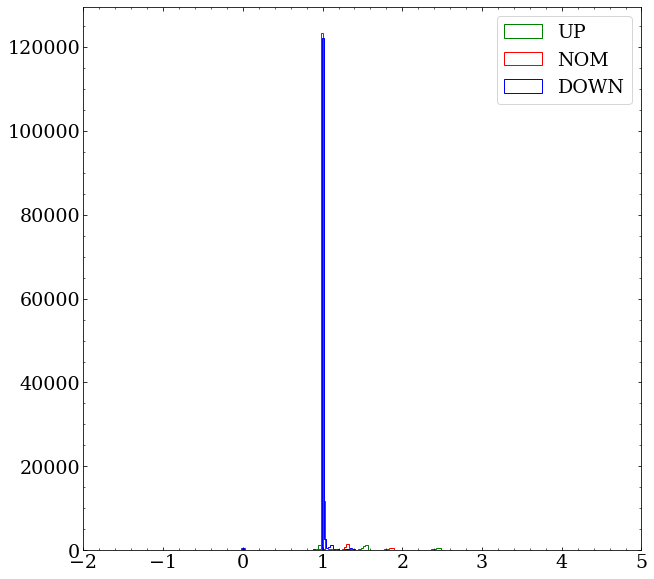

In [180]:
plt.hist(up, bins=200, histtype='step', color='green', label="UP")
plt.hist(nom, bins=200, histtype='step', color='red', label="NOM")
plt.hist(down, bins=200, histtype='step', color='blue', label="DOWN")
plt.legend()
plt.xlim(-2,5)

In [59]:
np.histogram(ak.flatten(ak.to_numpy(up), axis=None))

IndexError: index -9223372036854775808 is out of bounds for axis 0 with size 11

In [132]:
e = events.Electron

In [133]:
e.pt

<Array [[], [12, 10.2], ... 5.15], [122, 18.3]] type='133026 * var * float32[par...'>

In [138]:
ak.max(e.pt, axis=1)

<Array [None, 12, None, ... None, 5.15, 122] type='133026 * ?float32'>

In [140]:
# gen = events.Genpart
gen = events.GenPart

gen['isb'] = (abs(gen.pdgId) == 5) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])

gen['isc'] = (abs(gen.pdgId) == 4) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])

gen['isTop'] = (abs(gen.pdgId) == 6) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])
genTops = gen[gen.isTop]
ttjet_weights = np.ones(event_size)
# if('TTJets' in dataset):
#     ttjet_weights = np.sqrt(get_ttbar_weight(genTops.pt.sum()) * get_ttbar_weight(genTops.pt.sum()))

gen['isW'] = (abs(gen.pdgId) == 24) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])
gen['isZ'] = (abs(gen.pdgId) == 23) & gen.hasFlags(['fromHardProcess', 'isLastCopy'])
gen['isA'] = (abs(gen.pdgId) == 22) & gen.hasFlags(['isPrompt', 'fromHardProcess', 'isLastCopy']) & (gen.status == 1)

In [141]:
genWs = gen[gen.isW & (gen.pt > 100)]
genZs = gen[gen.isZ & (gen.pt > 100)]
genDYs = gen[gen.isZ & (gen.mass > 30)]

In [143]:
ak.max(genWs.pt, axis=1)

<Array [None, 130, 136, ... 134, 107, 107] type='133026 * ?float32'>

In [144]:
genWs.pt

<Array [[], [130], [136], ... [107], [107]] type='133026 * var * float32[paramet...'>

In [ ]:
jes = {}
jesUp = {}
jesDown = {}
jes['sre'],   jesDown['sre'],   jesUp['sre'] = get_deepflav_weight['medium'](j_good_clean,j_good_clean.pt, j_good_clean.eta, j_good_clean.hadronFlavour, '+1', )
jes['srm'],   jesDown['srm'],   jesUp['srm'] = get_deepflav_weight['medium'](j_good_clean,j_good_clean.pt, j_good_clean.eta, j_good_clean.hadronFlavour, '+1', )
jes['ttbare'], jesDown['ttbare'], jesUp['ttbare'] = get_deepflav_weight['medium'](j_good_clean, j_good_clean.pt, j_good_clean.eta, j_good_clean.hadronFlavour, '2', )
jes['ttbarm'], jesDown['ttbarm'], jesUp['ttbarm'] = get_deepflav_weight['medium'](j_good_clean, j_good_clean.pt, j_good_clean.eta, j_good_clean.hadronFlavour, '2', )
jes['wjete'], jesDown['wjete'], jesUp['wjete'] = get_deepflav_weight['medium'](j_good_clean, j_good_clean.pt, j_good_clean.eta, j_good_clean.hadronFlavour, '0', )
jes['wjetm'], jesDown['wjetm'], jesUp['wjetm'] = get_deepflav_weight['medium'](j_good_clean, j_good_clean.pt, j_good_clean.eta, j_good_clean.hadronFlavour, '0', )  
